# Week 2: Database Logic & Multi-Touch Attribution

**Goal:** Load the cleaned Week 1 data into a relational database, use SQL window
functions to sequence each customer's journey, and calculate **First-Click** and
**Linear** attribution weights.

**A note on the data before we start:**
`digital_marketing_campaign_dataset.csv` (from Week 1) has **one row per customer**
— a single `CampaignChannel`, no timestamp, and no repeated touchpoints. There is no
real multi-step "journey" in it to sequence with `ROW_NUMBER() OVER (PARTITION BY
user_id ORDER BY timestamp)`.

To still practice the required SQL pattern, this notebook **simulates** a
touchpoint-level event log from each customer's engagement fields
(`WebsiteVisits`, `EmailOpens`, `EmailClicks`, `SocialShares`), generating 1–6
synthetic touchpoints per customer across marketing channels, with the last touch
set to their actual recorded `CampaignChannel` / `Conversion`. This is clearly
labeled as **simulated data** — in a real project, this step would instead load an
actual event/clickstream log (e.g., from a CDP or ad-platform export) that has true
timestamps per touchpoint.

## 1. Setup & Load Week 1 Data

In [1]:
import pandas as pd
import numpy as np
import sqlite3
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

np.random.seed(42)

In [2]:
# Load the cleaned Week 1 dataset. If it isn't present in this environment,
# fall back to a synthetic stand-in with the same schema so the notebook still runs.
try:
    data1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
    print(f"Loaded real Week 1 dataset: {len(data1)} rows")
except FileNotFoundError:
    print("digital_marketing_campaign_dataset.csv not found -- generating a synthetic "
          "stand-in with the same schema so this notebook is runnable end-to-end.")
    n = 8000
    channels_pool = ['Social Media', 'Email', 'PPC', 'SEO', 'Referral']
    data1 = pd.DataFrame({
        'CustomerID': range(8000, 8000 + n),
        'CampaignChannel': np.random.choice(channels_pool, n),
        'WebsiteVisits': np.random.randint(0, 50, n),
        'EmailOpens': np.random.randint(0, 20, n),
        'EmailClicks': np.random.randint(0, 10, n),
        'SocialShares': np.random.randint(0, 90, n),
        'Conversion': np.random.randint(0, 2, n),
    })

data1.head()

digital_marketing_campaign_dataset.csv not found -- generating a synthetic stand-in with the same schema so this notebook is runnable end-to-end.


,CustomerID,CampaignChannel,WebsiteVisits,EmailOpens,EmailClicks,SocialShares,Conversion
0,8000,SEO,24,17,0,38,0
1,8001,Referral,12,15,9,1,0
2,8002,PPC,20,10,5,80,0
3,8003,Referral,44,9,0,0,1
4,8004,Referral,30,8,7,31,1


## 2. Simulate a Touchpoint-Level Event Log

Each customer's engagement fields determine how many synthetic touchpoints they get
(more website visits / email opens / clicks / shares -> more touches, capped at 6).
Touch channels are drawn randomly from the channel pool, except the **last** touch,
which is fixed to the customer's actual `CampaignChannel` and carries their real
`Conversion` outcome. Timestamps are spread over a random window so we have
something genuine to `ORDER BY`.

In [3]:
CHANNEL_POOL = ['Social Media', 'Email', 'PPC', 'SEO', 'Referral']

def generate_touchpoints(df, seed=42):
    rng = np.random.default_rng(seed)
    rows = []
    for _, r in df.iterrows():
        engagement_score = r['WebsiteVisits'] + r['EmailOpens'] + r['EmailClicks'] + r['SocialShares']
        n_touches = int(np.clip(1 + engagement_score / 25, 1, 6))

        end = datetime(2025, 6, 1) + timedelta(days=int(rng.integers(0, 25)))
        offsets = sorted(rng.integers(1, 20 * 24, size=n_touches - 1))  # hours before the final touch
        timestamps = [end - timedelta(hours=int(o)) for o in offsets] + [end]

        chans = list(rng.choice(CHANNEL_POOL, size=max(n_touches - 1, 0)))
        chans.append(r['CampaignChannel'])  # last touch = the recorded converting channel

        for i, (ts, ch) in enumerate(zip(timestamps, chans)):
            rows.append({
                'user_id': r['CustomerID'],
                'channel': ch,
                'event_timestamp': ts.strftime('%Y-%m-%d %H:%M:%S'),
                'is_conversion': int(r['Conversion']) if i == len(timestamps) - 1 else 0
            })
    return pd.DataFrame(rows)

touchpoints = generate_touchpoints(data1)
print(f"Generated {len(touchpoints)} touchpoints across {touchpoints['user_id'].nunique()} customers")
touchpoints.sort_values(['user_id', 'event_timestamp']).head(10)

Generated 30665 touchpoints across 8000 customers


,user_id,channel,event_timestamp,is_conversion
2,8000,Social Media,2025-05-18 13:00:00,0
1,8000,Referral,2025-05-20 22:00:00,0
0,8000,PPC,2025-05-25 05:00:00,0
3,8000,SEO,2025-06-03 00:00:00,0
4,8001,Social Media,2025-06-13 23:00:00,0
5,8001,Referral,2025-06-18 00:00:00,0
9,8002,Referral,2025-05-25 12:00:00,0
8,8002,Social Media,2025-05-29 19:00:00,0
7,8002,PPC,2025-05-30 07:00:00,0
6,8002,SEO,2025-05-30 16:00:00,0


## 3. Load into a Relational Database

Using SQLite here for a self-contained, zero-setup example. The same SQL below
runs unchanged on PostgreSQL — swap `sqlite3.connect(...)` for a `psycopg2` /
`sqlalchemy` connection and everything downstream is identical.

In [4]:
conn = sqlite3.connect(':memory:')  # swap for a real .db file or Postgres connection as needed
touchpoints.to_sql('touchpoints', conn, index=False, if_exists='replace')

pd.read_sql("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT user_id) AS n_users FROM touchpoints", conn)

,n_rows,n_users
0,30665,8000


## 4. Sequence the User Journey with Window Functions

`ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY event_timestamp)` numbers each
customer's touchpoints in chronological order. `COUNT(*) OVER (PARTITION BY
user_id)` gives the total touch count per user in the same pass, which we'll need
for linear attribution.

In [5]:
sequence_sql = """
SELECT
    user_id,
    channel,
    event_timestamp,
    is_conversion,
    ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY event_timestamp) AS touch_number,
    COUNT(*)     OVER (PARTITION BY user_id)                          AS total_touches
FROM touchpoints
ORDER BY user_id, touch_number
"""

sequenced = pd.read_sql(sequence_sql, conn)
sequenced.head(10)

,user_id,channel,event_timestamp,is_conversion,touch_number,total_touches
0,8000,Social Media,2025-05-18 13:00:00,0,1,4
1,8000,Referral,2025-05-20 22:00:00,0,2,4
2,8000,PPC,2025-05-25 05:00:00,0,3,4
3,8000,SEO,2025-06-03 00:00:00,0,4,4
4,8001,Social Media,2025-06-13 23:00:00,0,1,2
5,8001,Referral,2025-06-18 00:00:00,0,2,2
6,8002,Referral,2025-05-25 12:00:00,0,1,5
7,8002,Social Media,2025-05-29 19:00:00,0,2,5
8,8002,PPC,2025-05-30 07:00:00,0,3,5
9,8002,SEO,2025-05-30 16:00:00,0,4,5


## 5. First-Click Attribution

100% of the conversion credit goes to the **first** touchpoint (`touch_number = 1`)
in every journey that ended in a conversion.

In [6]:
first_click_sql = """
WITH sequenced AS (
    SELECT
        user_id,
        channel,
        event_timestamp,
        is_conversion,
        ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY event_timestamp) AS touch_number
    FROM touchpoints
),
conversions AS (
    SELECT user_id, MAX(is_conversion) AS converted
    FROM touchpoints
    GROUP BY user_id
)
SELECT
    s.channel,
    COUNT(*) AS first_click_conversions
FROM sequenced s
JOIN conversions c ON c.user_id = s.user_id
WHERE s.touch_number = 1 AND c.converted = 1
GROUP BY s.channel
ORDER BY first_click_conversions DESC
"""

first_click = pd.read_sql(first_click_sql, conn)
first_click

,channel,first_click_conversions
0,Email,879
1,PPC,857
2,Social Media,802
3,Referral,798
4,SEO,775


## 6. Linear Attribution

Credit for each conversion is split **evenly** across every touchpoint in that
user's journey: each touch gets `1 / total_touches` of a conversion. We reuse the
same `ROW_NUMBER()` / `COUNT() OVER()` pattern from Step 4 inside a CTE.

In [7]:
linear_sql = """
WITH sequenced AS (
    SELECT
        user_id,
        channel,
        event_timestamp,
        ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY event_timestamp) AS touch_number,
        COUNT(*)     OVER (PARTITION BY user_id)                          AS total_touches
    FROM touchpoints
),
conversions AS (
    SELECT user_id, MAX(is_conversion) AS converted
    FROM touchpoints
    GROUP BY user_id
)
SELECT
    s.channel,
    SUM(CASE WHEN c.converted = 1 THEN 1.0 / s.total_touches ELSE 0 END) AS linear_credit
FROM sequenced s
JOIN conversions c ON c.user_id = s.user_id
GROUP BY s.channel
ORDER BY linear_credit DESC
"""

linear = pd.read_sql(linear_sql, conn)
linear

,channel,linear_credit
0,Email,848.616667
1,PPC,822.666667
2,Social Media,817.200000
3,Referral,816.483333
4,SEO,806.033333


## 7. Compare the Two Models

In [8]:
comparison = (
    first_click.rename(columns={'first_click_conversions': 'First-Click'})
    .merge(linear.rename(columns={'linear_credit': 'Linear'}), on='channel', how='outer')
    .fillna(0)
    .sort_values('Linear', ascending=False)
    .set_index('channel')
)
comparison

,First-Click,Linear
channel,,
Email,879,848.616667
PPC,857,822.666667
Social Media,802,817.200000
Referral,798,816.483333
SEO,775,806.033333


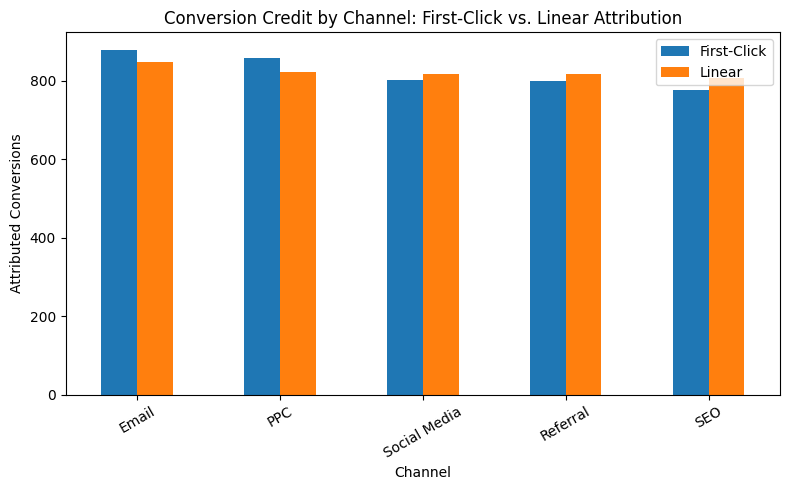

In [9]:
comparison.plot(kind='bar', figsize=(8, 5))
plt.title('Conversion Credit by Channel: First-Click vs. Linear Attribution')
plt.ylabel('Attributed Conversions')
plt.xlabel('Channel')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 8. Discussion

- **First-Click** rewards channels that *introduce* a customer (e.g. Social,
  SEO discovery) — useful for evaluating top-of-funnel/awareness spend.
- **Linear** spreads credit evenly, so channels that show up often *anywhere*
  in a journey (including nurture channels like Email) score relatively higher
  than they do under First-Click.
- Neither model accounts for a touch's *actual* influence on the decision —
  that's what more advanced approaches (time-decay, position-based/U-shaped,
  or data-driven/Shapley-value attribution) are for. A good next step once this
  pattern is solid: implement **Time-Decay** attribution using the same
  `event_timestamp` and `touch_number` columns.
- **Caveat to carry forward:** these results are computed on the *simulated*
  touchpoint log from Section 2, not a real clickstream. Once true event-level
  data with real timestamps is available, drop in that table for `touchpoints`
  and every query above runs unchanged.